Part 1: Explore, preprocess and quality-control the data

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

data = pd.read_csv("NHANES_20212023_merged_filtered 1.csv")
codebook = pd.read_csv("NHANES_20212023_codebook_filtered 1.csv", encoding="cp1252")

print(data.shape)
data.head()

(11933, 486)


,SEQN,SDDSRVYR,RIDSTATR,RIAGENDR,RIDAGEYR,RIDAGEMN,RIDRETH1,RIDRETH3,RIDEXMON,RIDEXAGM,...,DBQ930,DBQ935,DBQ940,DBQ945,ECD070A,ECD070B,ECQ080,ECQ090,WHQ030E,MCQ080E
0,130378,12,2,1,43,NaN,5,6,2.0,NaN,...,2.0,1.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN
1,130379,12,2,1,66,NaN,3,3,2.0,NaN,...,2.0,1.0,2.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN
2,130380,12,2,2,44,NaN,2,2,1.0,NaN,...,1.0,1.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN
3,130381,12,2,2,5,NaN,5,7,1.0,71.0,...,NaN,NaN,NaN,NaN,6.0,9.0,NaN,NaN,3.0,2.0
4,130382,12,2,1,2,NaN,3,3,2.0,34.0,...,NaN,NaN,NaN,NaN,8.0,0.0,NaN,NaN,3.0,2.0


Inladen (read_csv, shape, head)

Wat: data en codebook inlezen. Het codebook vraagt cp1252 als encoding.
Waarom: je moet weten wat je hebt voor je iets aanpast.
Afleiding: 11.933 personen en 485 variabelen (de 486e kolom is het ID SEQN). In de preview staan veel NaN.
Volgende: ID als index zetten en uitzoeken wat de kolommen zijn.

In [6]:
data = data.set_index("SEQN")
print(data.shape)

codebook.head(20)
codebook["file"].value_counts()

(11933, 485)


file
VOCWB_L     77
FAR_L       43
BIOPRO_L    41
TST_L       34
DEMO_L      27
DBQ_L       26
CBC_L       22
BMX_L       21
PFAS_L      19
FASTQX_L    18
PBCD_L      16
FOLFMS_L    15
FFMR_L      14
BPXO_L      11
IHGEM_L     10
TRIGLY_L     9
VID_L        9
ALQ_L        8
ALB_CR_L     7
ECQ_L        6
BCHE_L       4
COT_L        4
HEPBD_L      4
HEPC_L       4
INS_L        4
HDL_L        3
TCHOL_L      3
FERTIN_L     3
FOLATE_L     3
HEPE_L       3
HSCRP_L      3
GLU_L        3
TFR_L        3
AGP_L        2
GHB_L        2
HEPA_L       2
HEPB_S_L     2
UCPREG_L     1
Name: count, dtype: int64

set_index("SEQN") en codebook["file"].value_counts()

Wat: het ID wordt de rijnaam. Daarna tel je hoeveel kolommen uit elk NHANES-bestand komen.
Waarom: een ID is geen feature, en de bestandsnamen vertellen wat voor soort variabelen je hebt.
Afleiding: een mix van demografie, metingen, vragenlijsten en labtesten uit zo'n 40 bestanden.
Volgende: kijken hoeveel er ontbreekt.

count    485.000000
mean      53.602338
std       22.908341
min        0.000000
25%       38.422861
50%       41.221822
75%       75.345680
max      100.000000
dtype: float64


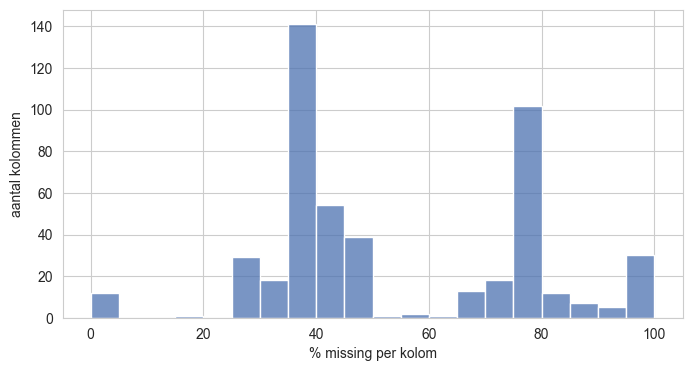

In [7]:
missing = data.isnull().mean() * 100          # % missing per kolom
print(missing.describe())

plt.figure(figsize=(8, 4))
sns.histplot(missing, bins=20)
plt.xlabel("% missing per kolom")
plt.ylabel("aantal kolommen")
plt.show()

Histogram van missing_%

Wat: per kolom het percentage NaN, in een histogram.
Waarom: missing values zijn de eerste kwaliteitscheck. Je beantwoordt er "waar ontbreken ze en waarom" mee.
Afleiding: de missings zitten in blokken (rond 0%, 40%, 78% en 100%). Dat komt door de opzet van NHANES, niet door toeval: niet iedereen kreeg elke test.
Volgende: een drempel kiezen. Er is een gap tussen 50 en 65%.

In [8]:
keep = missing[missing <= 60].index
data_f = data[keep]
print(f"Kolommen: {data.shape[1]} -> {data_f.shape[1]}")

# hoeveel volledige rijen blijven er over?
print("Volledige rijen:", data_f.dropna().shape[0])

Kolommen: 485 -> 297
Volledige rijen: 2811


Kolommen met ≤60% missing houden, dan dropna()

Wat: 485 → 297 kolommen. Daarna blijven alleen rijen over die overal een waarde hebben.
Waarom: een kolom die bijna leeg is, laat te weinig personen over. De drempel volgt uit de gap in het histogram.
Afleiding: 2.811 volledige rijen, genoeg om mee te werken.
Volgende: controleren wie die 2.811 zijn.

In [9]:
complete = data_f.dropna()

print("Alle personen:")
print(data["RIDAGEYR"].describe())

print("\nVolledige rijen:")
print(complete["RIDAGEYR"].describe())

print("\nAandeel vrouw (2) vs man (1):")
print(data["RIAGENDR"].value_counts(normalize=True))
print(complete["RIAGENDR"].value_counts(normalize=True))

Alle personen:
count    11933.000000
mean        38.317858
std         25.601990
min          0.000000
25%         13.000000
50%         37.000000
75%         62.000000
max         80.000000
Name: RIDAGEYR, dtype: float64

Volledige rijen:
count    2811.000000
mean       53.588403
std        16.622850
min        20.000000
25%        39.000000
50%        57.000000
75%        67.000000
max        80.000000
Name: RIDAGEYR, dtype: float64

Aandeel vrouw (2) vs man (1):
RIAGENDR
2    0.532808
1    0.467192
Name: proportion, dtype: float64
RIAGENDR
2    0.522234
1    0.477766
Name: proportion, dtype: float64


Vergelijking van leeftijd en geslacht (alle personen versus volledige rijen)

Wat: describe() en value_counts(normalize=True) voor beide groepen.
Waarom: een filter kan je steekproef scheeftrekken. Dat moet je weten.
Afleiding: alleen volwassenen blijven over (20-80 jaar, gemiddeld 54), met een gelijke man/vrouw-verdeling. Leeftijd 80 is top-coded. Je conclusies gelden dus alleen voor volwassenen.
Volgende: niet-biologische kolommen eruit halen.

In [10]:
cols = data_f.columns

lc_cols = [c for c in cols if c.endswith("LC") or c.endswith("L") and c.startswith("LBD") and data_f[c].nunique() <= 2]
wt_cols = [c for c in cols if c.startswith("WT")]
design_cols = ["SDMVSTRA", "SDMVPSU", "SDDSRVYR", "RIDSTATR"]

print("Gewichten:", wt_cols)
print("LC-vlaggen:", lc_cols)
print("Aantal:", len(lc_cols), len(wt_cols))

Gewichten: ['WTINT2YR', 'WTMEC2YR', 'WTPH2YR_HDL_L', 'WTPH2YR_TCHOL_L', 'WTPH2YR_CBC_L', 'WTPH2YR_FAR_L', 'WTPH2YR_FOLATE_L', 'WTPH2YR_FFMR_L', 'WTPH2YR_GHB_L', 'WTPH2YR_HEPA_L', 'WTPH2YR_HEPB_S_L', 'WTPH2YR_HEPBD_L', 'WTPH2YR_HEPC_L', 'WTPH2YR_HEPE_L', 'WTPH2YR_HSCRP_L', 'WTPH2YR_PBCD_L', 'WTPH2YR_IHGEM_L', 'WTPH2YR_FOLFMS_L', 'WTPH2YR_TST_L', 'WTPH2YR_BIOPRO_L', 'WTPH2YR_VID_L']
LC-vlaggen: ['URDUMALC', 'URDUCRLC', 'LBDBALC', 'LBDCHLC', 'LBDCOTLC', 'LBDHCOLC', 'LBDPANLC', 'LBDP1ALC', 'LBDPRALC', 'LBDPDALC', 'LBDPHALC', 'LBDPD3LC', 'LBDPD6LC', 'LBDPTALC', 'LBDPEDLC', 'LBDP1ELC', 'LBDPPELC', 'LBDPLGLC', 'LBDPGHLC', 'LBDP1GLC', 'LBDPNLLC', 'LBDPMRLC', 'LBDPNRLC', 'LBDPOLLC', 'LBDPPLLC', 'LBDPPMLC', 'LBDPSTLC', 'LBDRF1LC', 'LBDRF2LC', 'LBDRF3LC', 'LBDRF4LC', 'LBDRF5LC', 'LBDRF6LC', 'LBDHRPLC', 'LBDBPBLC', 'LBDBCDLC', 'LBDTHGLC', 'LBDBSELC', 'LBDBMNLC', 'LBDIHGLC', 'LBDBGELC', 'LBDBGMLC', 'LBDSF1LC', 'LBDSF2LC', 'LBDSF3LC', 'LBDSF4LC', 'LBDSF5LC', 'LBDSF6LC', 'LBD17HLC', 'LBDANDLC', 'LBDA

Lijsten van gewichten (WT…), LC-vlaggen en designvariabelen

Wat: je zoekt kolommen op naam.
Waarom: gewichten, vlaggen en designvariabelen zijn geen biologie. Ze zouden anders in PCA meespelen.
Afleiding: 21 gewichten en 66 vlaggen.
Volgende: de vlaggen eerst gebruiken en pas daarna weggooien.

In [11]:
# 1. Hoeveel waarden liggen onder de detectielimiet? (1 = onder LOD)
lod = (complete[lc_cols] == 1).mean() * 100
print(lod.sort_values(ascending=False).head(15))

# 2. Nu de niet-biologische kolommen weggooien
drop_cols = lc_cols + wt_cols + design_cols
drop_cols = [c for c in drop_cols if c in complete.columns]

df = complete.drop(columns=drop_cols)
print(f"Kolommen: {complete.shape[1]} -> {df.shape[1]}")

LBDBGELC    99.786553
LBDSF3LC    99.715404
LBDSF5LC    96.300249
LBDIHGLC    84.560655
LBDVD2LC    79.011028
LBDRF3LC    57.417289
LBDRF2LC    53.041622
LBDCOTLC    42.155816
LBDHCOLC    41.657773
LBDAMHLC    32.337247
LBDBGMLC    32.052650
LBDRF5LC    24.510850
LBDTHGLC    16.755603
URDUMALC     8.182142
LBDSF4LC     4.517965
dtype: float64
Kolommen: 297 -> 206


Percentage onder de detectielimiet (LOD) en drop

Wat: per vlag het aandeel waarden onder de LOD. Daarna gooi je de 87 kolommen weg (297 → 206).
Waarom: NHANES vult die waarden in met een constante (LOD/√2). Dat zorgt voor een kunstmatige piek.
Afleiding: voor 7 stoffen ligt meer dan 50% onder de LOD. Zij bevatten bijna geen echte variatie.
Volgende: zoeken welke meetkolommen bij die vlaggen horen.

In [12]:
# vlaggen met > 50% onder LOD
bad_flags = lod[lod > 50].index.tolist()
print(bad_flags)

# zoek de bijhorende metingen in het codebook
cb = codebook.set_index("variable")
for flag in bad_flags:
    print(flag, "->", cb.loc[flag, "label"])

['LBDRF2LC', 'LBDRF3LC', 'LBDIHGLC', 'LBDBGELC', 'LBDSF3LC', 'LBDSF5LC', 'LBDVD2LC']
LBDRF2LC -> Folic acid, RBC cmt
LBDRF3LC -> 5-Formyl-tetrahydrofolate, RBC cmt
LBDIHGLC -> Mercury, inorganic comment code
LBDBGELC -> Mercury, ethyl comment code
LBDSF3LC -> 5-Formyl-tetrahydrofolate cmt
LBDSF5LC -> 5,10-Methenyl-tetrahydrofolate cmt
LBDVD2LC -> 25OHD2 comment code


In [13]:
for stof in ["Folic acid", "5-Formyl", "5,10-Methenyl", "Mercury, inorganic", "Mercury, ethyl", "25OHD2"]:
    print(cb[cb["label"].str.contains(stof, regex=False)][["label"]])
    print()

                             label
variable                          
LBXRF2SI  Folic acid, RBC (nmol/L)
LBDRF2LC       Folic acid, RBC cmt
LBXSF2SI       Folic acid (nmol/L)
LBDSF2LC            Folic acid cmt

                                            label
variable                                         
LBXRF3SI  5-Formyl-tetrahydrofolate, RBC (nmol/L)
LBDRF3LC       5-Formyl-tetrahydrofolate, RBC cmt
LBXSF3SI       5-Formyl-tetrahydrofolate (nmol/L)
LBDSF3LC            5-Formyl-tetrahydrofolate cmt

                                            label
variable                                         
LBXRF5SI  5,10-Methenyl-tetrahydrofolate (nmol/L)
LBDRF5LC  5,10-Methenyl-tetrahydrofolate, RBC cmt
LBXSF5SI  5,10-Methenyl-tetrahydrofolate (nmol/L)
LBDSF5LC       5,10-Methenyl-tetrahydrofolate cmt

                                    label
variable                                 
LBXIHG          Mercury, inorganic (ug/L)
LBDIHGSI      Mercury, inorganic (nmol/L)
LBDIHGLC  Mercury, 

In [14]:
too_many_lod = ["LBXRF2SI", "LBXRF3SI", "LBXIHG", "LBDIHGSI",
                "LBXBGE", "LBDBGESI", "LBXSF3SI", "LBXSF5SI", "LBXVD2MS"]
too_many_lod = [c for c in too_many_lod if c in df.columns]

df = df.drop(columns=too_many_lod)
print(f"Kolommen: {df.shape[1]}")

Kolommen: 197


Labels opzoeken in het codebook en 9 kolommen droppen (→ 197)

Wat: je koppelt de vlag via het label aan de meetkolom en verwijdert die.
Waarom: de namen volgen geen vast patroon, dus raden is riskant.
Afleiding: de 9 verwijderde kolommen zijn foliumzuurvormen, ethyl- en anorganisch kwik, en vitamine D2.
Volgende: dubbele eenheden zoeken.

In [15]:
import re

cb_df = cb.loc[[c for c in df.columns if c in cb.index], ["label"]].copy()
cb_df["basis"] = cb_df["label"].str.replace(r"\s*\(.*\)\s*$", "", regex=True).str.strip()

dubbels = cb_df[cb_df.duplicated("basis", keep=False)].sort_values("basis")
pd.set_option("display.max_rows", None)
pd.set_option("display.width", 200)
print(dubbels[["label"]])

                                             label
variable                                          
LBX17H             17a-hydroxyprogesterone (ng/dL)
LBD17HSI          17a-hydroxyprogesterone (nmol/L)
LBXSAL          Albumin, refrigerated serum (g/dL)
LBDSALSI         Albumin, refrigerated serum (g/L)
URXUMA                      Albumin, urine (ug/mL)
URXUMS                       Albumin, urine (mg/L)
LBXAND                     Androstenedione (ng/dL)
LBDANDSI                  Androstenedione (nmol/L)
LBXAMH              Anti-Mullerian hormone (ng/mL)
LBDAMHSI           Anti-Mullerian hormone (pmol/L)
LBXSBU                 Blood Urea Nitrogen (mg/dL)
LBDSBUSI              Blood Urea Nitrogen (mmol/L)
LBXBCD                        Blood cadmium (ug/L)
LBDBCDSI                    Blood cadmium (nmol/L)
LBXBPB                          Blood lead (ug/dL)
LBDBPBSI                       Blood lead (umol/L)
LBXBMN                      Blood manganese (ug/L)
LBDBMNSI                  Blood

In [16]:
dubbel_weg = [
    "LBD17HSI", "LBDSALSI", "URXUMS", "LBDANDSI", "LBDAMHSI", "LBDSBUSI",
    "LBDBCDSI", "LBDBPBSI", "LBDBMNSI", "LBDTHGSI", "LBDBSESI", "LBDSCHSI",
    "LBDSCRSI", "URXCRS", "LBDDHESI", "LBDHDDSI", "LBDESTSI", "LBDESOSI",
    "LBDES1SI", "LBDSGBSI", "LBDSGLSI", "LBDSIRSI", "LBDBGMSI", "LBDSPHSI",
    "LBDPG4SI", "LBDRFOSI", "LBDFOTSI", "LBDTSTSI", "LBDSTBSI", "LBDSCASI",
    "LBDTCSI", "LBDSTPSI", "LBDSTRSI", "LBDSUASI",
]
dubbel_weg = [c for c in dubbel_weg if c in df.columns]

# vastentijd samenvoegen
df["fast_hours"] = df["PHAFSTHR"] + df["PHAFSTMN"] / 60
dubbel_weg += ["PHAFSTHR", "PHAFSTMN"]

df = df.drop(columns=dubbel_weg)
print(f"Kolommen: {df.shape[1]}")

Kolommen: 162


C:\Users\mduca\AppData\Local\Temp\ipykernel_45460\2221659897.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["fast_hours"] = df["PHAFSTHR"] + df["PHAFSTMN"] / 60


Duplicaten via de basisnaam en dubbel_weg (→ 162)

Wat: je haalt de eenheid tussen haakjes uit het label. Kolommen met dezelfde basisnaam zijn dezelfde meting. Je houdt de conventionele versie en voegt vastentijd (uren en minuten) samen tot fast_hours.
Waarom: mg/dL en mmol/L bevatten dezelfde informatie. Die zou je dubbel meetellen in PCA.
Afleiding: 34 echte duplicaten. Vastentijd was geen duplicaat maar twee delen van één duur.
Volgende: de speciale codes in de vragenlijsten.

In [17]:
# alleen de vragenlijst-kolommen (uit de bestanden DBQ_L, ALQ_L, ECQ_L, DEMO_L)
vraag_prefix = ("DBQ", "DBD", "ALQ", "ECQ", "ECD", "DMD", "DMQ", "WHQ", "MCQ", "PHQ")
q_cols = [c for c in df.columns if c.startswith(vraag_prefix)]

print(len(q_cols), "vragenlijst-kolommen")

for c in q_cols:
    print(c, "|", cb.loc[c, "label"], "|", "n_unique:", df[c].nunique(), "| max:", df[c].max())

17 vragenlijst-kolommen
DMQMILIZ | Served active duty in US Armed Forces | n_unique: 2 | max: 2.0
DMDBORN4 | Country of birth | n_unique: 2 | max: 2.0
DMDEDUC2 | Education level - Adults 20+ | n_unique: 5 | max: 5.0
DMDMARTZ | Marital status | n_unique: 4 | max: 99.0
DMDHHSIZ | Total number of people in the Household | n_unique: 7 | max: 7
PHQ020 | Coffee or tea with cream or sugar? | n_unique: 2 | max: 2.0
PHQ030 | Alcohol, such as beer, wine, or liquor? | n_unique: 2 | max: 2.0
PHQ040 | Gum, mints, lozenges or cough drops | n_unique: 2 | max: 2.0
PHQ050 | Antacids, laxatives, or anti-diarrheals? | n_unique: 2 | max: 2.0
PHQ060 | Dietary supplements? | n_unique: 2 | max: 2.0
ALQ111 | Ever had a drink of any kind of alcohol | n_unique: 2 | max: 9.0
ALQ121 | Past 12 mos how often drink alc bev | n_unique: 13 | max: 99.0
ALQ151 | Ever have 4/5 or more drinks every day | n_unique: 3 | max: 9.0
DBQ930 | Main meal planner/preparer | n_unique: 2 | max: 2.0
DBQ935 | Shared meal planning/prepa

In [18]:
for c in ["DMDMARTZ", "ALQ111", "ALQ121", "ALQ151", "DBQ935"]:
    print(c, "|", cb.loc[c, "label"])
    print(df[c].value_counts(dropna=False).sort_index())
    print()

DMDMARTZ | Marital status
DMDMARTZ
1.0     1619
2.0      663
3.0      526
99.0       3
Name: count, dtype: int64

ALQ111 | Ever had a drink of any kind of alcohol
ALQ111
1.0    2809
9.0       2
Name: count, dtype: int64

ALQ121 | Past 12 mos how often drink alc bev
ALQ121
0.0     441
1.0     102
2.0     200
3.0     279
4.0     310
5.0     247
6.0     327
7.0     199
8.0     134
9.0     287
10.0    282
77.0      2
99.0      1
Name: count, dtype: int64

ALQ151 | Ever have 4/5 or more drinks every day
ALQ151
1.0     526
2.0    2284
9.0       1
Name: count, dtype: int64

DBQ935 | Shared meal planning/preparing duty
DBQ935
1.0    1461
2.0    1349
9.0       1
Name: count, dtype: int64



In [19]:
df["DMDMARTZ"] = df["DMDMARTZ"].replace([77, 99], np.nan)
df["ALQ111"]   = df["ALQ111"].replace([7, 9], np.nan)
df["ALQ121"]   = df["ALQ121"].replace([77, 99], np.nan)
df["ALQ151"]   = df["ALQ151"].replace([7, 9], np.nan)
df["DBQ935"]   = df["DBQ935"].replace([7, 9], np.nan)

print("Rijen met een NaN:", df.isnull().any(axis=1).sum())

df = df.dropna()
print("Dataset nu:", df.shape)

Rijen met een NaN: 10
Dataset nu: (2801, 162)


Codes 7/9/77/99 detecteren, vervangen door NaN en rijen verwijderen (→ 2.801)

Wat: je controleert max en value_counts, vervangt de codes door NaN en doet dropna.
Waarom: "refused" en "don't know" zijn getallen die als echte meting zouden meetellen. Het is dezelfde val als PAD680 = 9999 in het regressienotebook.
Afleiding: ze kwamen maar 1 tot 3 keer voor per kolom, dus je verloor slechts 10 rijen.
Volgende: verdelingen bekijken.

In [20]:
# 1. Nominale/ordinale variabelen en codes: apart zetten
cat_cols = ["RIAGENDR", "RIDRETH1", "RIDRETH3", "RIDEXMON", "DMDBORN4", "DMQMILIZ",
            "DMDEDUC2", "DMDMARTZ", "BPAOARM",
            "PHQ020", "PHQ030", "PHQ040", "PHQ050", "PHQ060",
            "ALQ111", "ALQ151", "DBQ930", "DBQ935", "DBQ940", "DBQ945"]
cat_cols = [c for c in cat_cols if c in df.columns]

# 2. De rest = kandidaat-features (numeriek)
num_cols = [c for c in df.columns if c not in cat_cols]
print(len(cat_cols), "categorische kolommen;", len(num_cols), "numerieke kolommen")

# 3. Welke numerieke kolommen zijn sterk scheef?
skew = df[num_cols].skew().sort_values(ascending=False)
print(skew.head(15))
print("Aantal met |skew| > 1:", (skew.abs() > 1).sum())

20 categorische kolommen; 142 numerieke kolommen
LBXSCK      37.343911
LBXEST      30.420660
LBXBPB      19.073955
URXUMA      17.576873
LBXESO      16.933935
LBXSGTSI    13.790147
URDACT      13.526260
LBXNRBC     12.272268
LBXSF2SI    11.121087
LBXPG4      10.463285
LBXSASSI    10.424916
LBX17H       8.766699
LBXES1       8.505083
LBXBSE       8.084308
LBXHSCRP     7.857959
dtype: float64
Aantal met |skew| > 1: 79


Splitsing categorisch/numeriek en skew()

Wat: je zet nominale kolommen apart en berekent de scheefheid van de numerieke.
Waarom: categorieën zijn geen getallen (6 > 3 betekent niets), en scheve verdelingen verstoren schaling en PCA.
Afleiding: 79 van de 142 numerieke kolommen hadden |skew| > 1. Dat is gewoon rechtsscheve biologie.
Volgende: log1p toepassen.

Kolommen met negatieve waarden (geen log): []
          skew voor  skew na
LBXSCK        37.34     0.91
LBXEST        30.42     0.24
LBXBPB        19.07     1.97
URXUMA        17.58     0.70
LBXESO        16.93     1.16
LBXSGTSI      13.79     1.28
URDACT        13.53     1.26
LBXNRBC       12.27     3.35
LBXSF2SI      11.12     4.55
LBXPG4        10.46     2.30
LBXSASSI      10.42     1.61
LBX17H         8.77    -0.21
LBXES1         8.51    -0.20
LBXBSE         8.08     1.90
LBXHSCRP       7.86     1.08
Nog |skew| > 1 na log: 38


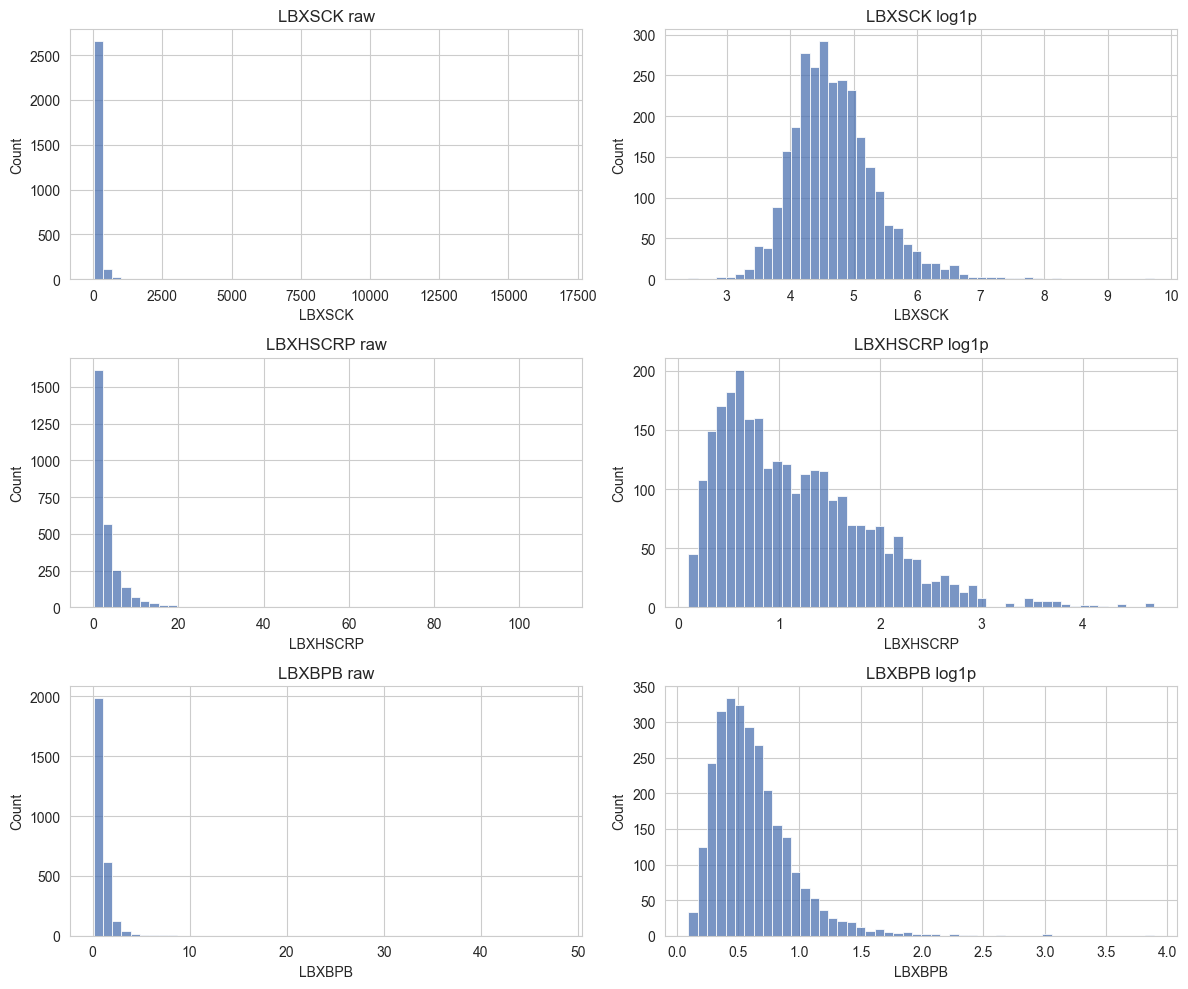

In [21]:
# 1. Kandidaten: scheve kolommen, enkel als er geen negatieve waarden in zitten
scheef = skew[skew.abs() > 1].index
negatief = [c for c in scheef if df[c].min() < 0]
print("Kolommen met negatieve waarden (geen log):", negatief)

log_cols = [c for c in scheef if c not in negatief]

# 2. Transformeren op een kopie
df_log = df.copy()
df_log[log_cols] = np.log1p(df_log[log_cols])

# 3. Scheefheid voor en na vergelijken
vergelijking = pd.DataFrame({
    "skew voor": df[log_cols].skew(),
    "skew na": df_log[log_cols].skew(),
}).sort_values("skew voor", ascending=False)
print(vergelijking.head(15).round(2))
print("Nog |skew| > 1 na log:", (vergelijking["skew na"].abs() > 1).sum())

# 4. Voor/na-plot van een paar kolommen
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(12, 10))
for row, col in zip(axes, ["LBXSCK", "LBXHSCRP", "LBXBPB"]):
    sns.histplot(df[col], bins=50, ax=row[0])
    sns.histplot(df_log[col], bins=50, ax=row[1])
    row[0].set_title(f"{col} raw")
    row[1].set_title(f"{col} log1p")
plt.tight_layout()
plt.show()

log1p op een kopie (df_log)

Wat: je transformeert de scheve kolommen en vergelijkt de skew voor en na.
Waarom: het kan met nullen overweg en het kapt de staarten in. Je vergelijkt op een kopie om je data niet kapot te maken.
Afleiding: de extreemste skews zakten sterk (37 → 0,9). 38 kolommen bleven scheef, wat acceptabel is.
Volgende: kijken of er nog bijna-constante kolommen zijn.

In [22]:
for c in ["LBXSF2SI", "LBXNRBC"]:
    print(c, "| aandeel van de meest voorkomende waarde:",
          df[c].value_counts(normalize=True).iloc[0].round(2))

LBXSF2SI | aandeel van de meest voorkomende waarde: 0.01
LBXNRBC | aandeel van de meest voorkomende waarde: 0.5


In [23]:
# 1. log-getransformeerde data overnemen (maar één keer uitvoeren!)
df = df_log.copy()

# 2. LBXNRBC verwijderen (50% dezelfde waarde)
df = df.drop(columns=["LBXNRBC"])

# 3. numerieke kolommen opnieuw bepalen
num_cols = [c for c in df.columns if c not in cat_cols]
print(df.shape, len(num_cols), "numeriek")

(2801, 161) 141 numeriek


LBXSF2SI en LBXNRBC controleren, LBXNRBC droppen

Wat: je kijkt naar het aandeel van de meest voorkomende waarde.
Waarom: een kolom waar de helft dezelfde waarde heeft, draagt weinig informatie.
Afleiding: LBXSF2SI is niet constant en blijft. LBXNRBC is een grensgeval en ging eruit.
Volgende: outliers.

In [24]:
scaled = (df[num_cols] - df[num_cols].mean()) / df[num_cols].std()

extreem = (scaled.abs() > 5).sum().sort_values(ascending=False)
print(extreem.head(15))

df["n_extreem"] = (scaled.abs() > 5).sum(axis=1)
print(df["n_extreem"].describe())

LBXHCR      54
LBDHCI      37
LBXSF2SI    31
LBXSGL      20
LBXGH       18
LBXPRA      18
LBXBCD      15
LBDHBG      13
LBXRDW      11
LBXMCHSI    11
LBXSASSI    10
LBXPPL       9
LBXPPE       9
LBXBPB       8
LBXBSE       8
dtype: int64
count    2801.000000
mean        0.145305
std         0.507747
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         6.000000
Name: n_extreem, dtype: float64


Outliers (|z| > 5 per kolom en n_extreem per persoon)

Wat: je telt extreme waarden per feature en per persoon.
Waarom: de opdracht vraagt of er afwijkende stalen of features zijn, en of dat techniek of biologie is.
Afleiding: de extreme waarden zijn grotendeels biologisch: glucose en HbA1c (diabetes), cadmium (roken), arachidonzuur en folaten (voeding/supplementen). Geen enkel staal wijkt op veel kolommen tegelijk af (maximaal 5 extreme waarden per persoon). Er zijn dus geen stalen om te verwijderen.
Volgende: nagaan of er kolommen zijn die eigenlijk categorieën of constanten zijn.

In [25]:
# enkel kolommen die ook in de originele data staan (fast_hours niet)
check_cols = [c for c in num_cols if c in data.columns]

kandidaten = [c for c in check_cols if data.loc[df.index, c].nunique() <= 5]
for c in kandidaten:
    print(c, "|", cb.loc[c, "label"], "|", sorted(data.loc[df.index, c].dropna().unique()))

BPAOCSZ | Coded cuff size - oscillometric | [np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0)]
BMDSTATS | Body Measures Component Status Code | [np.float64(1.0)]
LBDBANO | Basophils number (1000 cells/uL) | [np.float64(0.0), np.float64(0.1), np.float64(0.2), np.float64(0.3)]
PHDSESNZ | Session in which SP was examined | [np.float64(0.0), np.float64(1.0)]
LBXHA | Hepatitis A antibody | [np.float64(1.0), np.float64(2.0), np.float64(3.0)]
LBXHBS | Hepatitis B Surface Antibody | [np.float64(1.0), np.float64(2.0)]
LBXHBC | Hepatitis B core antibody | [np.float64(1.0), np.float64(2.0)]
LBDHBG | Hepatitis B surface antigen | [np.float64(1.0), np.float64(2.0)]
LBDHD | Hepatitis D antibody (anti-HDV) | [np.float64(2.0)]
LBXHCR | Hepatitis C RNA | [np.float64(1.0), np.float64(2.0), np.float64(3.0)]
LBDHCI | Hepatitis C Antibody (confirmed) | [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0)]
LBDHEG | Hepatitis E IgG (anti-HEV) | [np.float64(1.0), np.float64(2.

In [26]:
# 1. Constante kolommen weg
df = df.drop(columns=["BMDSTATS", "LBDHD"])

# 2. Categorische kolommen: alles uit kandidaten behalve de basofielen en de constante
nieuw_cat = [c for c in kandidaten if c not in ["LBDBANO", "BMDSTATS", "LBDHD"]]
cat_cols = list(dict.fromkeys(cat_cols + nieuw_cat))   # geen dubbels

# 3. log1p ongedaan maken voor die kolommen (terug naar de originele waarden)
df[nieuw_cat] = data.loc[df.index, nieuw_cat]

# 4. Numerieke kolommen opnieuw bepalen
cat_cols = [c for c in cat_cols if c in df.columns]
num_cols = [c for c in df.columns if c not in cat_cols and c != "n_extreem"]
print(df.shape)
print(len(cat_cols), "categorisch;", len(num_cols), "numeriek")

(2801, 160)
29 categorisch; 130 numeriek


kandidaten (≤5 unieke waarden) en verplaatsen naar cat_cols

Wat: je zoekt kolommen met weinig unieke waarden, zet hepatitis-uitslagen, manchetmaat en sessie als categorisch, en verwijdert 2 constante kolommen (BMDSTATS, LBDHD).
Waarom: een zeldzame categorie is geen outlier, en een getal als code (1/2/3) mag niet als meting in PCA.
Afleiding: 29 categorische en 130 numerieke kolommen. Basofielen (LBDBANO) is een echte telling en blijft numeriek.
Volgende: schalen en PCA.

(2801, 129) 0
[0.07898856 0.06715852]


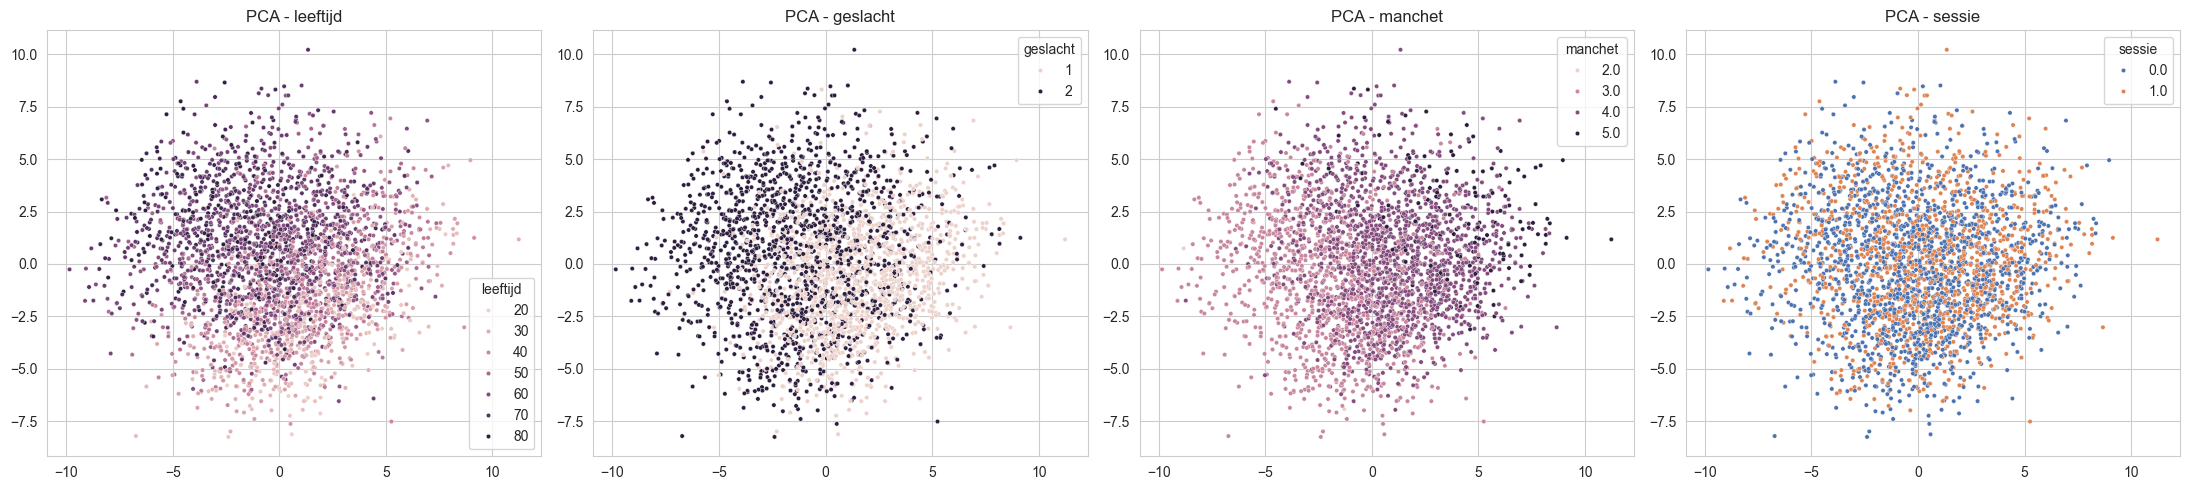

In [27]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# leeftijd als feature weglaten, anders is "clustert op leeftijd" triviaal
feat_cols = [c for c in num_cols if c != "RIDAGEYR"]

X = df[feat_cols]
X_scaled = pd.DataFrame(StandardScaler().fit_transform(X), index=X.index, columns=X.columns)
print(X_scaled.shape, X_scaled.isnull().sum().sum())   # tweede getal moet 0 zijn

pca = PCA(n_components=2).fit(X_scaled)
pca_xy = pca.transform(X_scaled)
print(pca.explained_variance_ratio_)

# kleurvariabelen uit de originele data
meta = pd.DataFrame({
    "leeftijd": data.loc[df.index, "RIDAGEYR"],
    "geslacht": data.loc[df.index, "RIAGENDR"],
    "manchet": data.loc[df.index, "BPAOCSZ"],     # check de naam in je data
    "sessie": data.loc[df.index, "PHDSESNZ"],
})

fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, var in zip(axes, meta.columns):
    sns.scatterplot(x=pca_xy[:, 0], y=pca_xy[:, 1], hue=meta[var], ax=ax, s=10)
    ax.set_title(f"PCA - {var}")
plt.tight_layout()
plt.show()

StandardScaler en PCA, gekleurd op leeftijd, geslacht, manchet en sessie

Wat: je schaalt de 129 features (zonder leeftijd) en projecteert op 2 assen.
Waarom: de eenheden verschillen sterk. Leeftijd laat je weg zodat een leeftijdsgradiënt een echte controle is. Kleuren op metadata toont of de structuur biologisch of technisch is.
Afleiding: PC1 en PC2 verklaren samen maar 14.6%. Er is een gradiënt volgens geslacht en zwakker volgens leeftijd. De sessie toont geen scheiding, dus geen batcheffect.
Volgende: niet-lineaire methoden proberen.

In [28]:
%pip install umap-learn

Note: you may need to restart the kernel to use updated packages.


C:\Users\mduca\anaconda3\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
C:\Users\mduca\anaconda3\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


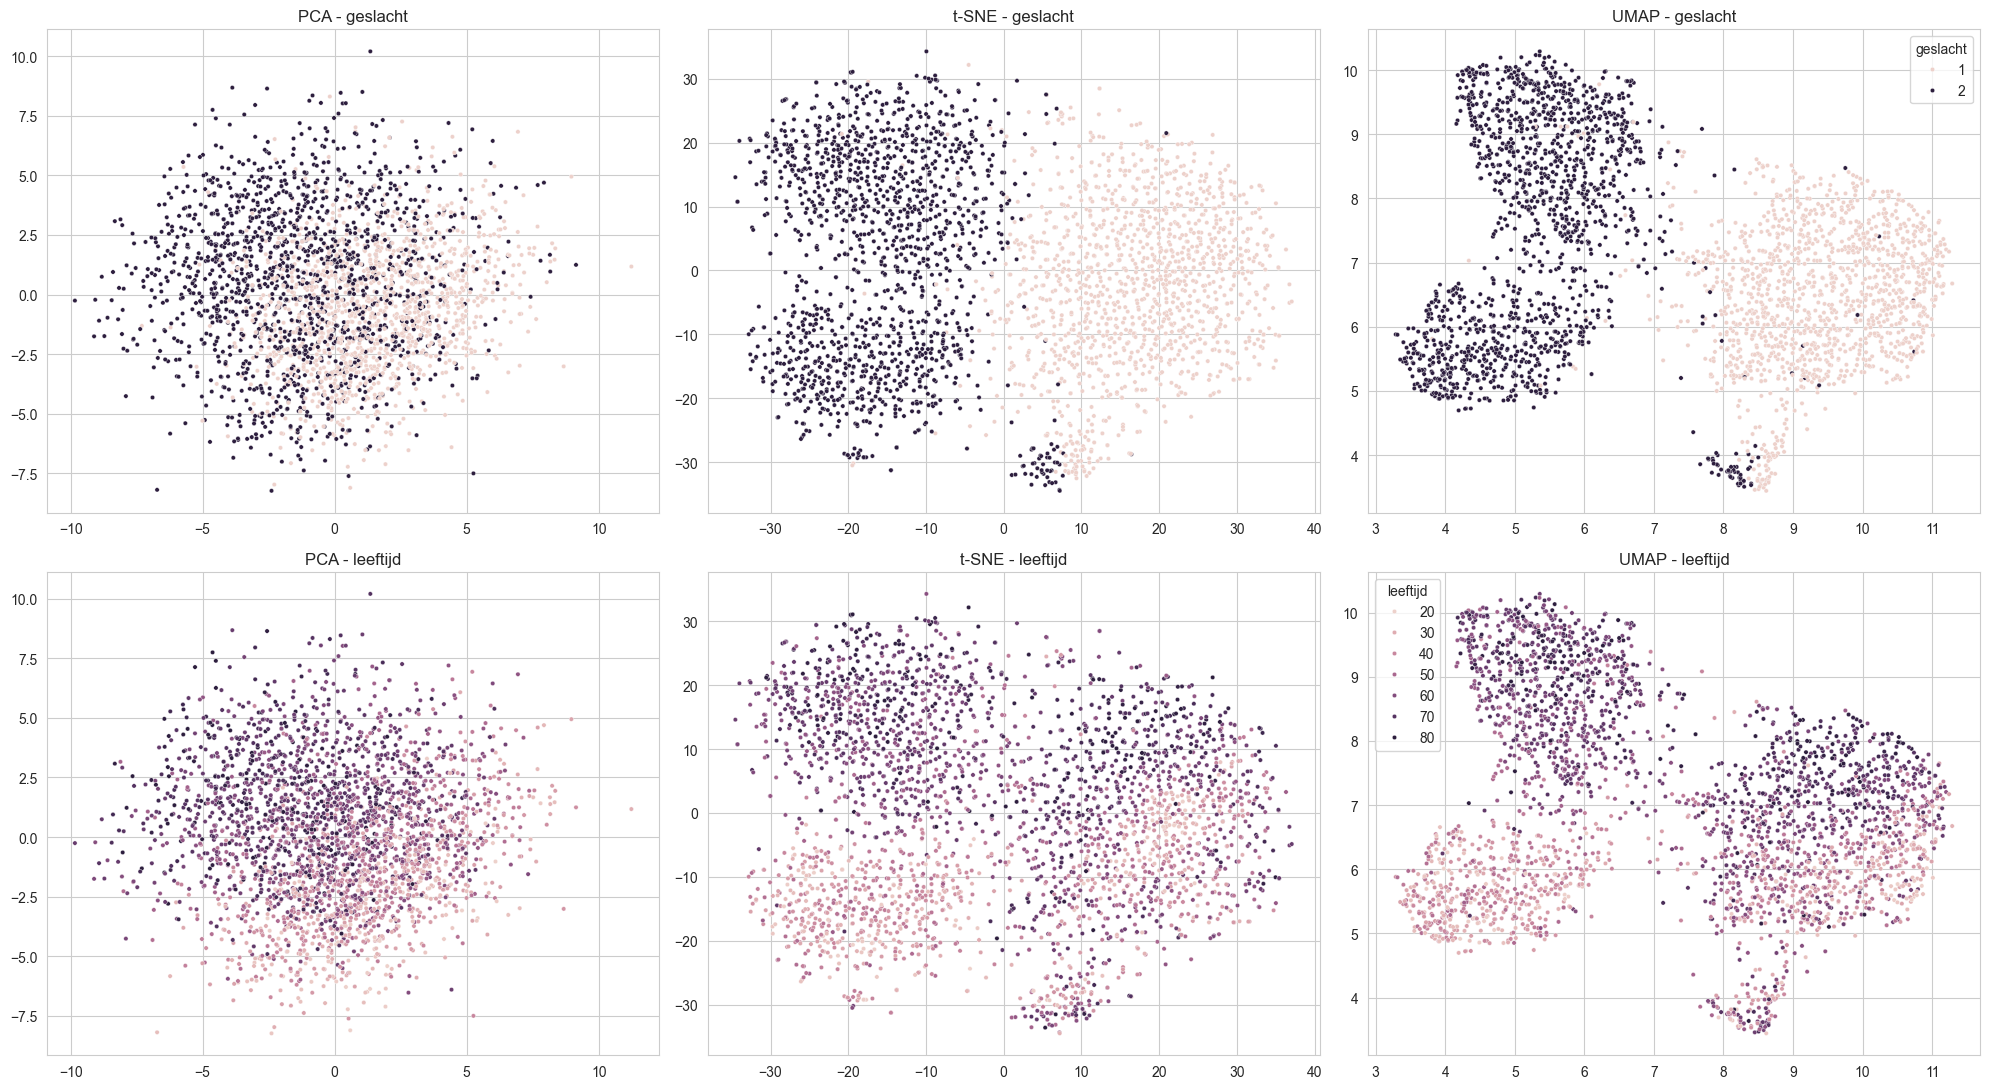

In [29]:
import umap
from sklearn.manifold import TSNE

# 1. t-SNE en UMAP met standaardinstellingen
tsne_xy = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(X_scaled)
umap_xy = umap.UMAP(n_components=2, n_neighbors=15, random_state=42).fit_transform(X_scaled)

fig, axes = plt.subplots(2, 3, figsize=(20, 11))
for row, var in zip(axes, ["geslacht", "leeftijd"]):
    for ax, xy, name in zip(row, [pca_xy, tsne_xy, umap_xy], ["PCA", "t-SNE", "UMAP"]):
        sns.scatterplot(x=xy[:, 0], y=xy[:, 1], hue=meta[var], ax=ax, s=10,
                        legend=(name == "UMAP"))
        ax.set_title(f"{name} - {var}")
plt.tight_layout()
plt.show()

UMAP en t-SNE (nadat je umap-learn installeerde)

Wat: niet-lineaire 2D-inbeddingen.
Waarom: PCA ziet alleen lineaire structuur.
Afleiding: geslacht is scherp gescheiden. Vrouwen vormen twee wolken (jong en oud) en mannen één. Daarnaast is er een klein groepje onderaan.

In [30]:
groepen = {
    "links boven (oud)":    (umap_xy[:, 0] < 7)   & (umap_xy[:, 1] > 7.3),
    "links onder (jong)":   (umap_xy[:, 0] < 7)   & (umap_xy[:, 1] < 6.7),
    "rechts (mannen)":      (umap_xy[:, 0] > 7.5) & (umap_xy[:, 1] > 4.6),
    "klein groepje onder":  (umap_xy[:, 0] > 7.6) & (umap_xy[:, 0] < 9.2) & (umap_xy[:, 1] < 4.4),
}

for naam, g in groepen.items():
    print(f"{naam}: {g.sum()} personen | aandeel vrouw: {(meta[g]['geslacht'] == 2).mean():.2f} "
          f"| mediane leeftijd: {meta[g]['leeftijd'].median():.0f}")
    print(X_scaled[g][["LBXFSH", "LBXLUH", "LBXAMH", "LBXEST"]].mean().round(2).to_dict())
    print()

links boven (oud): 810 personen | aandeel vrouw: 0.99 | mediane leeftijd: 65
{'LBXFSH': 1.28, 'LBXLUH': 1.14, 'LBXAMH': -1.11, 'LBXEST': -1.01}

links onder (jong): 542 personen | aandeel vrouw: 0.99 | mediane leeftijd: 36
{'LBXFSH': -0.61, 'LBXLUH': -0.41, 'LBXAMH': 0.02, 'LBXEST': 1.13}

rechts (mannen): 1241 personen | aandeel vrouw: 0.02 | mediane leeftijd: 58
{'LBXFSH': -0.56, 'LBXLUH': -0.56, 'LBXAMH': 0.74, 'LBXEST': 0.16}

klein groepje onder: 105 personen | aandeel vrouw: 0.43 | mediane leeftijd: 50
{'LBXFSH': -0.32, 'LBXLUH': -0.26, 'LBXAMH': 0.27, 'LBXEST': 0.12}



In [31]:
g = groepen["klein groepje onder"]
print(X_scaled[g].mean().sort_values().tail(8))
print(X_scaled[g].mean().sort_values().head(8))

LBXPMR    1.346600
LBXP1A    1.350281
LBXPNR    1.671433
LBXPOL    1.787157
LBXPDA    1.845143
LBXP1G    2.185344
LBXPPM    2.834700
LBXPST    2.865072
dtype: float64
LBXPRA   -3.725526
LBXPD3   -2.464589
LBXPTA   -1.965258
LBXPD6   -1.877419
LBXPHA   -1.768883
LBXPPE   -1.148110
LBXPGH   -0.911949
LBXPAN   -0.887531
dtype: float64


Groepen in de UMAP karakteriseren

Wat: je geeft de wolken in UMAP een naam via hun coördinaten en kijkt naar geslacht, leeftijd en hormonen.
Waarom: zo zie je of de structuur biologisch is.
Afleiding: links boven zijn 810 personen (99% vrouw, mediane leeftijd 65, hoge FSH en LH, lage AMH en oestradiol): vermoedelijk vrouwen na de menopauze. Links onder zijn 542 personen (99% vrouw, mediaan 36 jaar, hoge oestradiol): vrouwen vóór de menopauze. Rechts zijn 1.241 personen (98% man). Dat is dus biologie (geslacht, leeftijd, hormonale status). Een klein groepje van 105 personen (43% vrouw, mediaan 50 jaar) is niet verklaard.
Volgende: nagaan wat dat kleine groepje onderscheidt.

C:\Users\mduca\anaconda3\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
C:\Users\mduca\anaconda3\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
C:\Users\mduca\anaconda3\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change

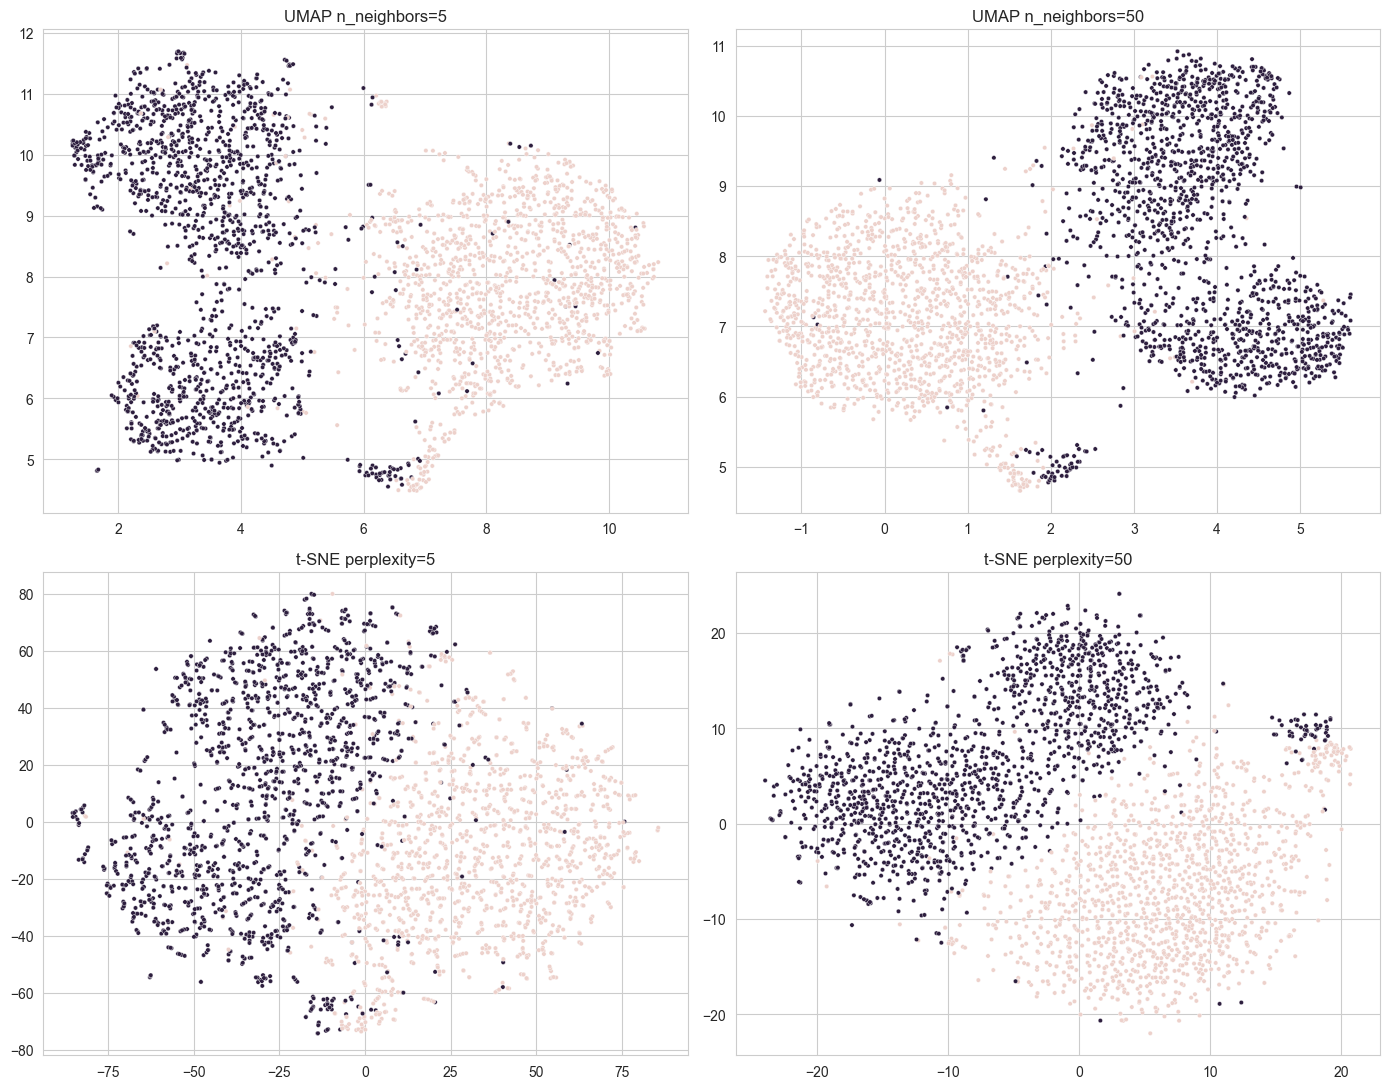

In [32]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11))

for ax, n in zip(axes[0], [5, 50]):
    xy = umap.UMAP(n_neighbors=n, random_state=42).fit_transform(X_scaled)
    sns.scatterplot(x=xy[:, 0], y=xy[:, 1], hue=meta["geslacht"], ax=ax, s=10, legend=False)
    ax.set_title(f"UMAP n_neighbors={n}")

for ax, p in zip(axes[1], [5, 50]):
    xy = TSNE(perplexity=p, random_state=42).fit_transform(X_scaled)
    sns.scatterplot(x=xy[:, 0], y=xy[:, 1], hue=meta["geslacht"], ax=ax, s=10, legend=False)
    ax.set_title(f"t-SNE perplexity={p}")

plt.tight_layout()
plt.show()

UMAP met n_neighbors 5/50 en t-SNE met perplexity 5/50

Wat: dezelfde plot met andere instellingen.
Waarom: vormen en afstanden in t-SNE en UMAP hangen sterk af van de instellingen. Alleen wat blijft staan, is betrouwbaar.
Afleiding: de scheiding tussen mannen en vrouwen en de twee vrouwenwolken blijven bij alle instellingen bestaan. Dat patroon is dus betrouwbaar.
Volgende: de groepen karakteriseren.

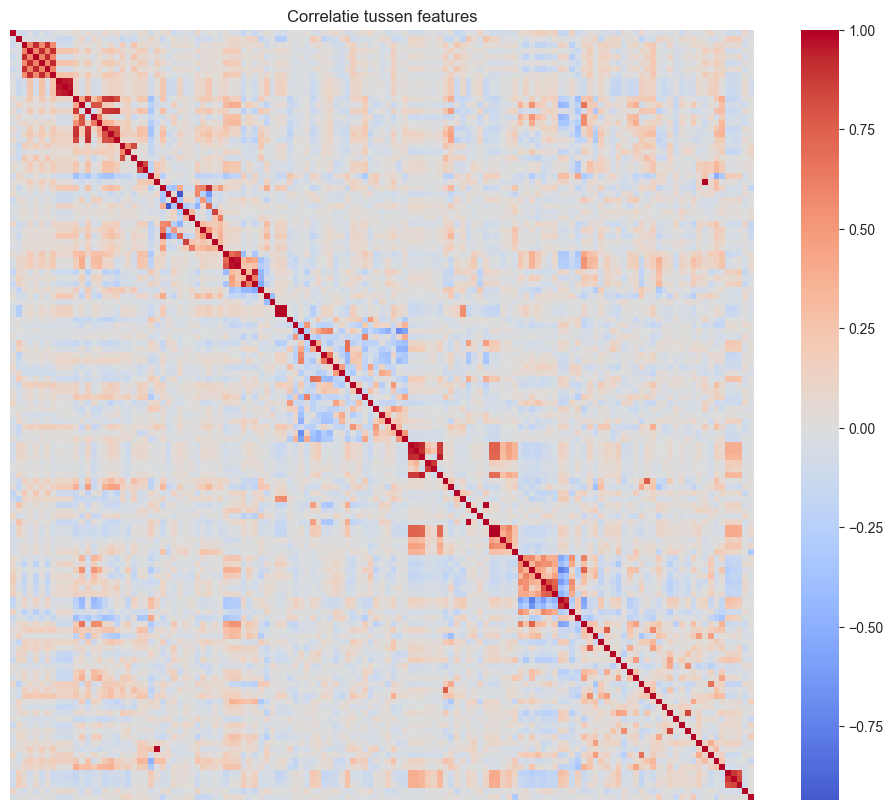

Aantal sterk gecorreleerde paren (|r| > 0.9): 24


In [33]:
corr = X_scaled.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, xticklabels=False, yticklabels=False)
plt.title("Correlatie tussen features")
plt.show()

# hoeveel paren zijn sterk gecorreleerd?
sterk = (corr.abs() > 0.9).sum().sum() - corr.shape[0]
print("Aantal sterk gecorreleerde paren (|r| > 0.9):", sterk // 2)

In [34]:
corr = X_scaled.corr().abs()
paren = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
paren = paren[paren > 0.9].sort_values(ascending=False)
for (a, b), r in paren.items():
    print(f"{a} - {b}: {r:.2f} | {cb.loc[a,'label']} / {cb.loc[b,'label']}")

LBDFOT - LBXSF1SI: 0.99 | Serum total folate (ng/mL) / 5-Methyl-tetrahydrofolate (nmol/L)
LBXTC - LBXSCH: 0.99 | Total Cholesterol (mg/dL) / Cholesterol, refrigerated serum (mg/dL)
LBXTHG - LBXBGM: 0.99 | Blood mercury, total (ug/L) / Mercury, methyl (ug/L)
LBXCOT - LBXHCOT: 0.99 | Cotinine, Serum (ng/mL) / Hydroxycotinine, Serum (ng/mL)
LBXHGB - LBXHCT: 0.97 | Hemoglobin (g/dL) / Hematocrit (%)
BPXOPLS2 - BPXOPLS3: 0.96 | Pulse - 2nd oscillometric reading / Pulse - 3rd oscillometric reading
BPXOPLS1 - BPXOPLS2: 0.96 | Pulse - 1st oscillometric reading / Pulse - 2nd oscillometric reading
LBDRFO - LBDRF7SI: 0.96 | RBC folate (ng/mL) / Total Folate, RBC (nmol/L)
LBXRF1SI - LBXRF6SI: 0.95 | 5-Methyl-tetrahydrofolate, RBC (nmol/L) / MeFox oxidation product, RBC (nmol/L)
BPXOPLS1 - BPXOPLS3: 0.94 | Pulse - 1st oscillometric reading / Pulse - 3rd oscillometric reading
LBXMCVSI - LBXMCHSI: 0.94 | Mean cell volume (fL) / Mean cell hemoglobin (pg)
LBXLYPCT - LBXNEPCT: 0.93 | Lymphocyte percent 

Correlatieheatmap en de lijst met |r| > 0.9 (24 paren)

Wat: je toont welke features sterk samenhangen.
Waarom: de laatste guiding question vraagt of de data geschikt zijn voor deel 2 en 3. Sterke collineariteit speelt daar een rol.
Afleiding: de meeste paren zijn herhaalde metingen (3× bloeddruk en pols) of dezelfde stof in andere vorm.
Volgende: optioneel opruimen.

In [35]:
df_clean = df.drop(columns=["n_extreem"])
df_clean.to_csv("nhanes_clean.csv")
print(df_clean.shape)

(2801, 159)


## Documentatie van de preprocessing

| Stap | Beslissing | Reden | Effect |
|---|---|---|---|
| Missings | kolommen met >60% missing verwijderd | gap tussen 50 en 65% in het histogram; subsample-tests | 485 → 297 kolommen |
| Volledige rijen | alleen volledige rijen | genoeg samples over | 11.933 → 2.811 (enkel volwassenen 20-80) |
| Gewichten, design, detectielimiet-vlaggen | verwijderd | geen biologie | → 206 kolommen |
| >50% onder detectielimiet | 9 metingen verwijderd | vooral ingevulde constante (LOD/√2) | → 197 |
| Dubbele eenheden | conventionele versie behouden, vastentijd samengevoegd | zelfde informatie | → 162 |
| Speciale codes | 7/9/77/99 → NaN, rijen verwijderd | geen echte metingen | 2.811 → 2.801 |
| Scheve variabelen | log1p op 79 kolommen | rechtsscheve labwaarden | skew sterk gedaald |
| LBXNRBC | verwijderd | 50% dezelfde waarde | -1 kolom |
| Categorisch | 29 kolommen apart (o.a. hepatitis, manchetmaat) | geen metingen | 130 numeriek |
| Constanten | BMDSTATS, LBDHD verwijderd | geen informatie | |
| Standaardisatie | StandardScaler, leeftijd niet als feature | verschillende eenheden | 129 features |

## Antwoorden op de guiding questions

**Samples en features:** oorspronkelijk 11.933 × 485. Na opschonen 2.801 volwassenen met 130 numerieke en 29 categorische variabelen (129 numerieke features in PCA/UMAP).

**Missings:** de ontbrekende waarden zitten in blokken: labtesten werden bij subsamples afgenomen en vragenlijsten gelden enkel voor volwassenen. Kolommen met >60% missing werden verwijderd en daarna alleen volledige rijen gehouden.

**Afwijkend gedrag:** geen enkel staal wijkt op veel variabelen af (max. 5). Extreme waarden per variabele zijn biologisch. Een klein groepje van 105 personen in UMAP is niet verklaard.

**Voorbewerking:** log1p, standaardisatie, verwijderen van dubbele eenheden en niet-biologische kolommen, en categorische variabelen apart houden.

**Clustering:** op biologie (geslacht, leeftijd/menopauze), niet op techniek: de onderzoekssessie geeft geen scheiding.

**Geschiktheid voor deel 2 en 3:** ja, met aandachtspunten: sterke geslachtsstructuur, 24 sterk gecorreleerde paren (regularisatie of feature selectie), en alleen volwassenen. Opmerking: leeftijd is top-coded op 80.

test

Test Janne

Test Xena

Test Maxence

# Part 2: Formulate and test your own research question

## Research question
In adults, is there an association between HDL cholesterol levels and long-term blood sugar levels (HbA1c), and does the strength or direction of this association differ between men and women, after adjusting for age?

## Hypothesis
We expect that lower HDL cholesterol levels are associated with higher long-term blood sugar levels, independent of age. Furthermore, we expect that this association is not equally strong for both sexes.

- **H0:** After adjusting for age, the association between HDL and HbA1c is the same for men and women (interaction term = 0).

- **H1:** After adjusting for age, the association differs between men and women (interaction term ≠ 0). Two-sided test.

## Variables
| Role | Variable | Type |
|---|---|---|
| Outcome | `LBXGH` (HbA1c) | continuous |
| Explanatory variable | `LBDHDD` (HDL-cholesterol) | continuous |
| Moderator | `RIAGENDR` (1 = male, 2 = female) | binary |
| Confounder | `RIDAGEYR` (age) | continuous |

## Model
`HbA1c = b0 + b1*HDL + b2*female + b3*(HDL x female) + b4*age + error`

- `b1` is the HDL slope for **men**
- `b1 + b3` is the HDL-slope for **women**
- `b3` is thz **difference in slope** (the interaction, which is the core of the research question)

In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
sns.set_palette("deep")
np.random.seed(42)

In [37]:
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan

## 1. Loading data and checking testability
First, verify that all required columns are present, check for any missing values, and determine the number of samples per group.

In [38]:
df = pd.read_csv("nhanes_clean.csv", index_col="SEQN")   
print("Dataset:", df.shape)

needed = ["LBXGH", "LBDHDD", "RIAGENDR", "RIDAGEYR"]
missing_cols = [c for c in needed if c not in df.columns]
assert not missing_cols, f"Missing columns: {missing_cols}"

d = df[needed].copy()
print("NaN per column:\n", d.isnull().sum())
print("\nSamples per sex (1 = male, 2 = female):")
print(d["RIAGENDR"].value_counts())

Dataset: (2801, 159)
NaN per column:
 LBXGH       0
LBDHDD      0
RIAGENDR    0
RIDAGEYR    0
dtype: int64

Samples per sex (1 = male, 2 = female):
RIAGENDR
2    1464
1    1337
Name: count, dtype: int64


**Check:** all columns are present, there are no NaN values, and both sexes have a sufficiently large number of samples for an interaction test.

## 2. Exploration and checking whether variables have been transformed
In Part 1, skewed variables were subjected to a `log1p` transformation. We need to determine whether this also applies to HbA1c and HDL, as this influences how we interpret the coefficients.

In [39]:
print(d[["LBXGH", "LBDHDD", "RIDAGEYR"]].describe().round(2))
print("\nSkewness:\n", d[["LBXGH", "LBDHDD", "RIDAGEYR"]].skew().round(2))

hba1c_logged = d["LBXGH"].max() < 4
hdl_logged   = d["LBDHDD"].max() < 10
print("\nHbA1c log-transformed?", hba1c_logged)
print("HDL log-transformed?  ", hdl_logged)

def hba1c_orig(x): return np.expm1(x) if hba1c_logged else x
def hdl_orig(x):   return np.expm1(x) if hdl_logged else x

         LBXGH   LBDHDD  RIDAGEYR
count  2801.00  2801.00   2801.00
mean      1.89     3.99     53.55
std       0.12     0.26     16.62
min       1.53     3.18     20.00
25%       1.82     3.81     39.00
50%       1.87     3.99     57.00
75%       1.92     4.17     67.00
max       2.76     4.93     80.00

Skewness:
 LBXGH       2.60
LBDHDD      0.21
RIDAGEYR   -0.28
dtype: float64

HbA1c log-transformed? True
HDL log-transformed?   True


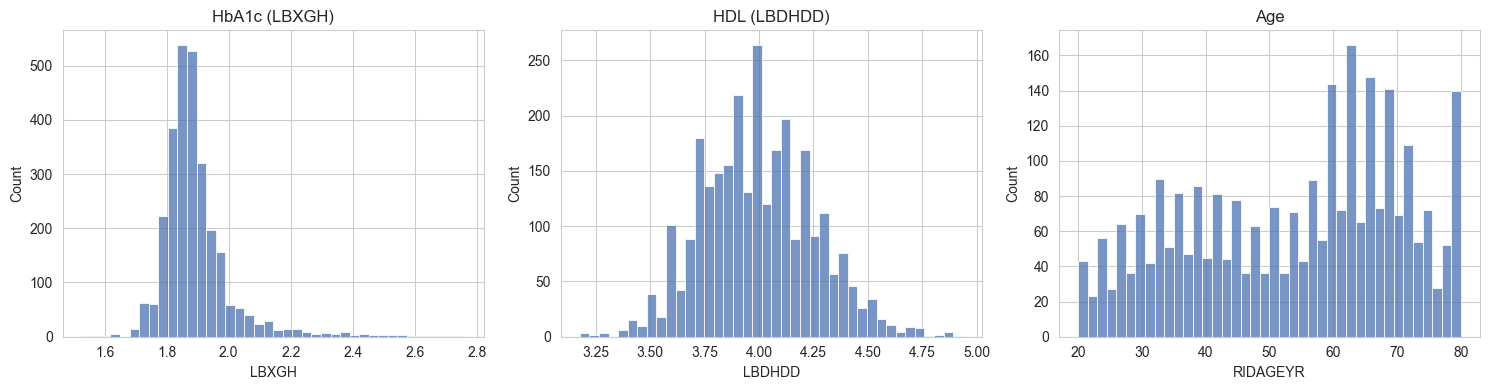

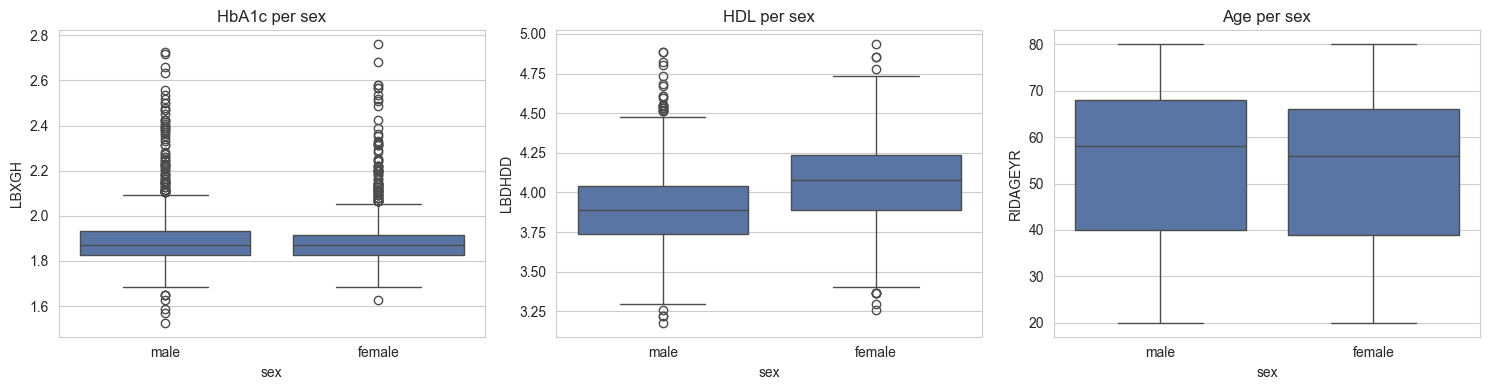

       LBXGH       LBDHDD       RIDAGEYR       
        mean   std   mean   std     mean    std
sex                                            
female  1.89  0.11   4.08  0.25    52.93  16.52
male    1.90  0.13   3.90  0.24    54.23  16.71


In [40]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(d["LBXGH"], bins=40, ax=axes[0]);   axes[0].set_title("HbA1c (LBXGH)")
sns.histplot(d["LBDHDD"], bins=40, ax=axes[1]);  axes[1].set_title("HDL (LBDHDD)")
sns.histplot(d["RIDAGEYR"], bins=40, ax=axes[2]); axes[2].set_title("Age")
plt.tight_layout(); plt.show()

d["sex"] = d["RIAGENDR"].map({1: "male", 2: "female"})
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, t in zip(axes, ["LBXGH", "LBDHDD", "RIDAGEYR"], ["HbA1c", "HDL", "Age"]):
    sns.boxplot(data=d, x="sex", y=col, ax=ax); ax.set_title(f"{t} per sex")
plt.tight_layout(); plt.show()

print(d.groupby("sex")[["LBXGH", "LBDHDD", "RIDAGEYR"]].agg(["mean", "std"]).round(2))

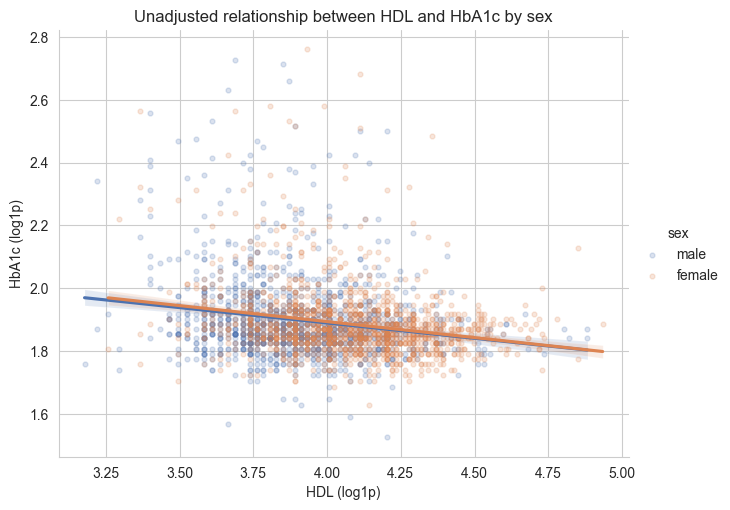

Correlatie (Pearson) HDL - HbA1c, per sex:
sex
female   -0.23
male     -0.18
dtype: float64


In [41]:
g = sns.lmplot(data=d, x="LBDHDD", y="LBXGH", hue="sex", height=5, aspect=1.3,
               scatter_kws={"alpha": 0.2, "s": 12})
g.set_axis_labels("HDL" + (" (log1p)" if hdl_logged else " (mg/dL)"),
                  "HbA1c" + (" (log1p)" if hba1c_logged else " (%)"))
plt.title("Unadjusted relationship between HDL and HbA1c by sex")
plt.show()

print("Correlatie (Pearson) HDL - HbA1c, per sex:")
print(d.groupby("sex").apply(lambda x: x["LBDHDD"].corr(x["LBXGH"])).round(3))

## 3. Preparation for the model
- **Centering** HDL and age: this makes `b2` (sex difference) interpretable for an average person and reduces collinearity with the interaction term.
- Sex as a 0/1 variable (`female`, with male as the reference).

In [47]:
d["hdl_c"] = d["LBDHDD"] - d["LBDHDD"].mean()
d["age_c"] = d["RIDAGEYR"] - d["RIDAGEYR"].mean()
d["vrouw"] = (d["RIAGENDR"] == 2).astype(int)
d["hdl_x_vrouw"] = d["hdl_c"] * d["vrouw"]       # nodig voor het sklearn-gedeelte
d.head()

,LBXGH,LBDHDD,RIAGENDR,RIDAGEYR,sex,hdl_c,age_c,vrouw,hdl_x_vrouw
SEQN,,,,,,,,,
130379,1.887070,4.110874,1,66,male,0.115970,12.44734,0,0.000000
130380,1.974081,3.912023,2,44,female,-0.082881,-9.55266,1,-0.082881
130393,1.840550,4.007333,1,39,male,0.012429,-14.55266,0,0.000000
130394,1.757858,3.891820,1,51,male,-0.103083,-2.55266,0,-0.000000
130399,1.902108,4.418841,1,68,male,0.423937,14.44734,0,0.000000


## 4. Fitting the model (statsmodels)
Three nested models:
- **M0**: age and sex only
- **M1**: M0 + HDL (main effect)
- **M2**: M1 + interaction between HDL and sex

The F-test comparing M1 and M2 provides the answer to the main research question.

In [48]:
m0 = smf.ols("LBXGH ~ age_c + vrouw", data=d).fit()
m1 = smf.ols("LBXGH ~ hdl_c + vrouw + age_c", data=d).fit()
m2 = smf.ols("LBXGH ~ hdl_c * vrouw + age_c", data=d).fit()

print(m2.summary())

                            OLS Regression Results                            
Dep. Variable:                  LBXGH   R-squared:                       0.157
Model:                            OLS   Adj. R-squared:                  0.156
Method:                 Least Squares   F-statistic:                     130.6
Date:                Fri, 27 Nov 2026   Prob (F-statistic):          2.24e-102
Time:                        13:35:08   Log-Likelihood:                 2236.0
No. Observations:                2801   AIC:                            -4462.
Df Residuals:                    2796   BIC:                            -4432.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept       1.8867      0.003    588.442      

In [49]:
# Modelvergelijking (geneste F-toetsen)
f01, p01, df01 = m0.compare_f_test(m1)
f12, p12, df12 = m1.compare_f_test(m2)

vergelijking = pd.DataFrame({
    "model": ["M0: leeftijd + geslacht", "M1: + HDL", "M2: + HDL x geslacht"],
    "R2": [m0.rsquared, m1.rsquared, m2.rsquared],
    "R2_adj": [m0.rsquared_adj, m1.rsquared_adj, m2.rsquared_adj],
    "AIC": [m0.aic, m1.aic, m2.aic],
    "F-toets t.o.v. vorig model (p)": [np.nan, p01, p12],
}).round(4)
vergelijking

,model,R2,R2_adj,AIC,F-toets t.o.v. vorig model (p)
0,M0: leeftijd + geslacht,0.0950,0.0944,-4265.7624,NaN
1,M1: + HDL,0.1574,0.1565,-4463.7069,NaN
2,M2: + HDL x geslacht,0.1574,0.1562,-4461.9052,NaN


In [50]:
# Coefficienten met 95%-betrouwbaarheidsinterval
coef = pd.DataFrame({
    "coef": m2.params,
    "ci_laag": m2.conf_int()[0],
    "ci_hoog": m2.conf_int()[1],
    "p": m2.pvalues,
}).round(4)
display(coef)

# Helling per geslacht ('simple slopes'), via een contrastvector over de parameters
namen = list(m2.params.index)
L_man = np.zeros(len(namen));   L_man[namen.index("hdl_c")] = 1
L_vrouw = L_man.copy();         L_vrouw[namen.index("hdl_c:vrouw")] = 1
slope_man   = m2.t_test(L_man)
slope_vrouw = m2.t_test(L_vrouw)
for naam, t in [("man", slope_man), ("vrouw", slope_vrouw)]:
    est = float(np.squeeze(t.effect)); lo, hi = np.squeeze(t.conf_int())
    print(f"HDL-helling bij {naam:5s}: {est:+.5f}  (95%-CI {lo:+.5f} tot {hi:+.5f}), p = {float(np.squeeze(t.pvalue)):.4g}")

,coef,ci_laag,ci_hoog,p
Intercept,1.8867,1.8804,1.8930,0.0000
hdl_c,-0.1197,-0.1447,-0.0948,0.0000
vrouw,0.0117,0.0030,0.0203,0.0082
hdl_c:vrouw,-0.0076,-0.0412,0.0260,0.6564
age_c,0.0024,0.0022,0.0027,0.0000


HDL-helling bij man  : -0.11973  (95%-CI -0.14467 tot -0.09478), p = 9.996e-21
HDL-helling bij vrouw: -0.12735  (95%-CI -0.15008 tot -0.10461), p = 1.663e-27


**How ​​to interpret this?**
- `hdl_c:vrouw` represents the difference in slope between women and men. If its 95% CI includes 0 (and p > 0.05), there is **no demonstrable difference**, and you retain the null hypothesis (H0).
- If the HDL slope is negative, it means that higher HDL levels are associated with lower HbA1c levels (as expected).
- If HbA1c and/or HDL have been log-transformed, a coefficient `b` corresponds to an approximate percentage change of `100 * b` per unit of the predictor. See also the explanation provided for each variable above.

## 5. Checking assumptions

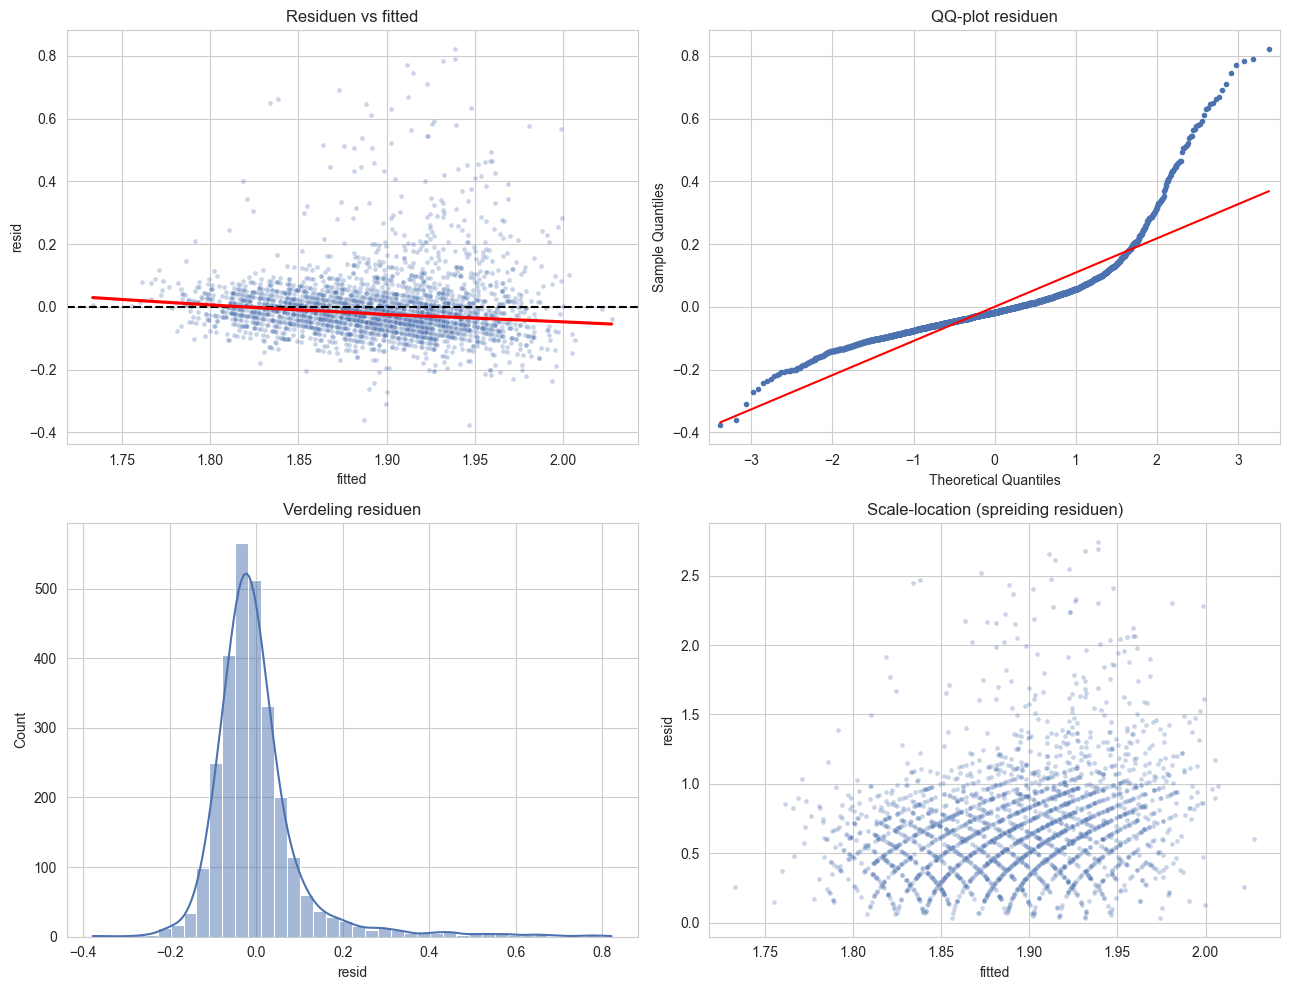

Breusch-Pagan (homoscedasticiteit): p = 2.065e-10  (p < 0.05 = heteroscedastisch)


In [51]:
d["resid"] = m2.resid
d["fitted"] = m2.fittedvalues

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

# 1. Residuen vs fitted (lineariteit + homoscedasticiteit)
sns.scatterplot(x="fitted", y="resid", data=d, alpha=0.3, s=12, ax=axes[0, 0])
axes[0, 0].axhline(0, color="k", ls="--")
sns.regplot(x="fitted", y="resid", data=d, lowess=True, scatter=False, color="red", ax=axes[0, 0])
axes[0, 0].set_title("Residuen vs fitted")

# 2. QQ-plot (normaliteit)
sm.qqplot(d["resid"], line="s", ax=axes[0, 1], markersize=3)
axes[0, 1].set_title("QQ-plot residuen")

# 3. Histogram residuen
sns.histplot(d["resid"], bins=40, kde=True, ax=axes[1, 0])
axes[1, 0].set_title("Verdeling residuen")

# 4. Scale-location
sns.scatterplot(x=d["fitted"], y=np.sqrt(np.abs(d["resid"] / d["resid"].std())), alpha=0.3, s=12, ax=axes[1, 1])
axes[1, 1].set_title("Scale-location (spreiding residuen)")
plt.tight_layout(); plt.show()

bp = het_breuschpagan(m2.resid, m2.model.exog)
print(f"Breusch-Pagan (homoscedasticiteit): p = {bp[1]:.4g}  (p < 0.05 = heteroscedastisch)")

     variabele   VIF
0    Intercept  1.00
1        hdl_c  2.52
2        vrouw  1.14
3  hdl_c:vrouw  2.33
4        age_c  1.02

Grootste Cook's distance: 0.0366  (richtlijn: > 4/n = 0.0014)
Aantal punten boven 4/n: 122


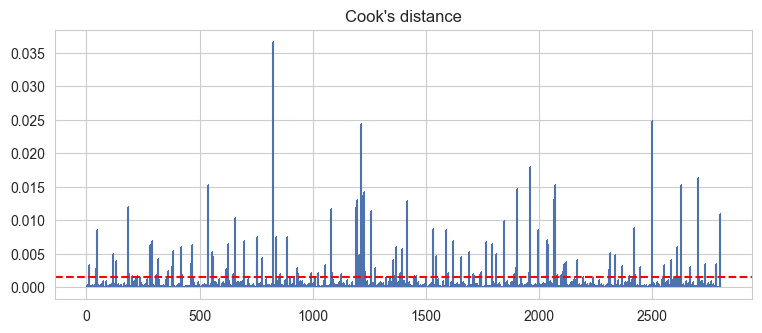

In [52]:
# Collineariteit (VIF) en invloedrijke punten (Cook's distance)
X = m2.model.exog
vif = pd.DataFrame({"variabele": m2.model.exog_names,
                    "VIF": [variance_inflation_factor(X, i) for i in range(X.shape[1])]}).round(2)
print(vif)

cooks = m2.get_influence().cooks_distance[0]
print(f"\nGrootste Cook's distance: {cooks.max():.4f}  (richtlijn: > 4/n = {4/len(d):.4f})")
print("Aantal punten boven 4/n:", int((cooks > 4/len(d)).sum()))

plt.figure(figsize=(9, 3.5))
plt.stem(cooks, markerfmt=",", basefmt=" ")
plt.axhline(4/len(d), color="red", ls="--"); plt.title("Cook's distance")
plt.show()

In [53]:
# Lineariteit extra testen: voegt een kwadratische HDL-term iets toe?
m2_q = smf.ols("LBXGH ~ hdl_c * vrouw + I(hdl_c**2) + age_c", data=d).fit()
f_q, p_q, _ = m2.compare_f_test(m2_q)
print(f"Kwadratische HDL-term: p = {p_q:.4g}  (p < 0.05 = lineariteit niet perfect)")

Kwadratische HDL-term: p = nan  (p < 0.05 = lineariteit niet perfect)


## 6. Sensitivity analyses
Checking whether the conclusion is robust.

In [54]:
# (a) Robuuste standaardfouten (HC3): beschermt tegen heteroscedasticiteit
m2_rob = smf.ols("LBXGH ~ hdl_c * vrouw + age_c", data=d).fit(cov_type="HC3")

# (b) Zonder (waarschijnlijke) diabetici: HbA1c >= 6.5 %
drempel = np.log1p(6.5) if hba1c_logged else 6.5
d_nodiab = d[d["LBXGH"] < drempel]
m2_nodiab = smf.ols("LBXGH ~ hdl_c * vrouw + age_c", data=d_nodiab).fit()

# (c) Extra interactie leeftijd x geslacht (menopause-effect): verdwijnt de HDL-interactie?
m2_age = smf.ols("LBXGH ~ hdl_c * vrouw + age_c * vrouw", data=d).fit()

term = "hdl_c:vrouw"
tabel = pd.DataFrame({
    "model": ["hoofdmodel M2", "robuuste SE (HC3)", f"zonder HbA1c >= 6.5 (n={len(d_nodiab)})", "+ leeftijd x geslacht"],
    "interactie_coef": [m.params[term] for m in [m2, m2_rob, m2_nodiab, m2_age]],
    "ci_laag": [m.conf_int().loc[term, 0] for m in [m2, m2_rob, m2_nodiab, m2_age]],
    "ci_hoog": [m.conf_int().loc[term, 1] for m in [m2, m2_rob, m2_nodiab, m2_age]],
    "p": [m.pvalues[term] for m in [m2, m2_rob, m2_nodiab, m2_age]],
}).round(5)
tabel

,model,interactie_coef,ci_laag,ci_hoog,p
0,hoofdmodel M2,-0.00762,-0.04120,0.02596,0.65640
1,robuuste SE (HC3),-0.00762,-0.04563,0.03039,0.69439
2,zonder HbA1c >= 6.5 (n=2522),-0.00800,-0.02586,0.00987,0.38006
3,+ leeftijd x geslacht,-0.00545,-0.03937,0.02848,0.75299


## 7. Predictive perspective 
In the practical sessions, you used `scikit-learn` with train/validation/test splits, cross-validation, R², and MAE. Here, we do the same to see whether the interaction term improves **prediction**. Do not expect a high R²: HDL explains only a small portion of the variation in HbA1c.

In [55]:
from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import r2_score, mean_absolute_error

y = d["LBXGH"]
sets = {
    "M0: leeftijd + geslacht":   ["age_c", "vrouw"],
    "M1: + HDL":                 ["age_c", "vrouw", "hdl_c"],
    "M2: + HDL x geslacht":      ["age_c", "vrouw", "hdl_c", "hdl_x_vrouw"],
}

# eerst de testset apart zetten, die gebruiken we maar een keer
X_trval, X_test, y_trval, y_test = train_test_split(d, y, test_size=0.2, random_state=42)

rijen = []
for naam, cols in sets.items():
    pipe = make_pipeline(StandardScaler(), LinearRegression())
    cv = cross_validate(pipe, X_trval[cols], y_trval, cv=5,
                        scoring=["r2", "neg_mean_absolute_error"])
    rijen.append({"model": naam,
                  "CV R2": cv["test_r2"].mean(), "sd R2": cv["test_r2"].std(),
                  "CV MAE": -cv["test_neg_mean_absolute_error"].mean()})
pd.DataFrame(rijen).round(4)

,model,CV R2,sd R2,CV MAE
0,M0: leeftijd + geslacht,0.0871,0.0293,0.0704
1,M1: + HDL,0.1448,0.0313,0.0685
2,M2: + HDL x geslacht,0.1444,0.0313,0.0685


Beste alpha: {'ridge__alpha': 10} | CV R2: 0.1444


,lineair (gestandaardiseerd),ridge (gestandaardiseerd)
age_c,0.0399,0.0397
vrouw,0.0053,0.0052
hdl_c,-0.0301,-0.0297
hdl_x_vrouw,-0.0019,-0.0022


Testset  R2 = 0.1852 | MAE = 0.0637


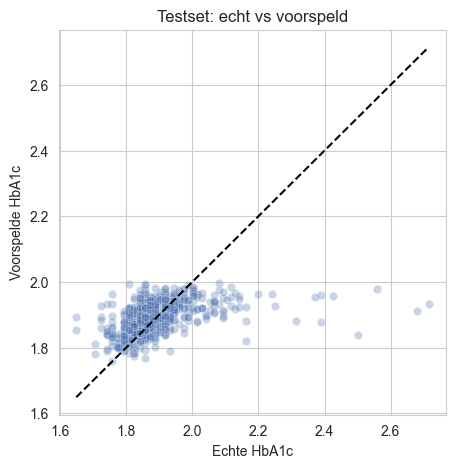

In [56]:
# Ridge als controle op stabiliteit van de coefficienten
cols = sets["M2: + HDL x geslacht"]
ridge = GridSearchCV(make_pipeline(StandardScaler(), Ridge()),
                     {"ridge__alpha": [0.01, 0.1, 1, 10, 100, 1000]}, cv=5, scoring="r2")
ridge.fit(X_trval[cols], y_trval)
print("Beste alpha:", ridge.best_params_, "| CV R2:", round(ridge.best_score_, 4))

lin = make_pipeline(StandardScaler(), LinearRegression()).fit(X_trval[cols], y_trval)
vergelijk = pd.DataFrame({
    "lineair (gestandaardiseerd)": lin[-1].coef_,
    "ridge (gestandaardiseerd)":   ridge.best_estimator_[-1].coef_,
}, index=cols).round(4)
display(vergelijk)

# Testset: eenmalig, enkel voor het eindmodel (M2)
test_pred = lin.predict(X_test[cols])
print(f"Testset  R2 = {r2_score(y_test, test_pred):.4f} | MAE = {mean_absolute_error(y_test, test_pred):.4f}")

plt.figure(figsize=(5, 5))
sns.scatterplot(x=y_test, y=test_pred, alpha=0.3)
lim = [y_test.min(), y_test.max()]
plt.plot(lim, lim, "k--"); plt.xlabel("Echte HbA1c"); plt.ylabel("Voorspelde HbA1c")
plt.title("Testset: echt vs voorspeld"); plt.show()

## 8. Figures

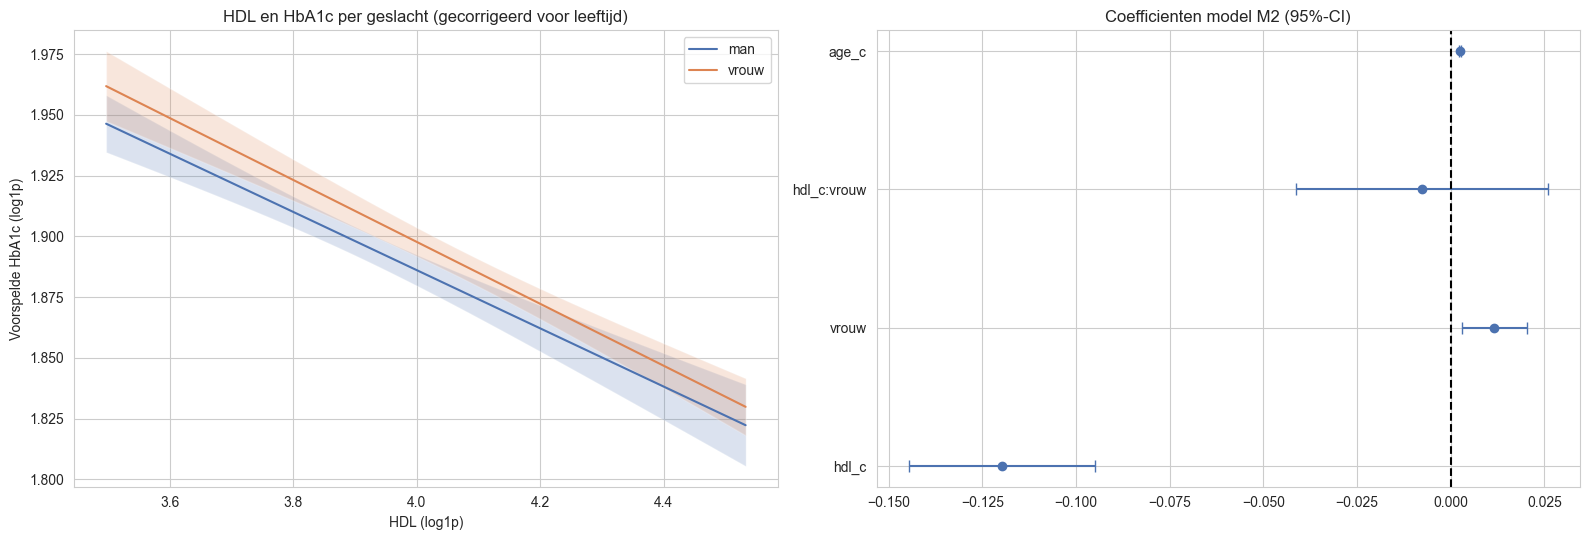

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# (1) interactieplot: gecorrigeerde voorspelling per geslacht (leeftijd op gemiddelde)
grid = np.linspace(d["hdl_c"].quantile(0.02), d["hdl_c"].quantile(0.98), 100)
for naam, v in [("man", 0), ("vrouw", 1)]:
    nieuw = pd.DataFrame({"hdl_c": grid, "vrouw": v, "age_c": 0.0})
    pred = m2.get_prediction(nieuw).summary_frame()
    x = grid + d["LBDHDD"].mean()
    axes[0].plot(x, pred["mean"], label=naam)
    axes[0].fill_between(x, pred["mean_ci_lower"], pred["mean_ci_upper"], alpha=0.2)
axes[0].set_xlabel("HDL" + (" (log1p)" if hdl_logged else " (mg/dL)"))
axes[0].set_ylabel("Voorspelde HbA1c" + (" (log1p)" if hba1c_logged else " (%)"))
axes[0].set_title("HDL en HbA1c per geslacht (gecorrigeerd voor leeftijd)")
axes[0].legend()

# (2) coefficientenplot
c = coef.drop(index="Intercept")
axes[1].errorbar(c["coef"], range(len(c)), xerr=[c["coef"] - c["ci_laag"], c["ci_hoog"] - c["coef"]],
                 fmt="o", capsize=4)
axes[1].axvline(0, color="k", ls="--")
axes[1].set_yticks(range(len(c))); axes[1].set_yticklabels(c.index)
axes[1].set_title("Coefficienten model M2 (95%-CI)")
plt.tight_layout(); plt.show()

In [58]:
# Automatische samenvatting voor je conclusie
b3, p3 = m2.params[term], m2.pvalues[term]
ci3 = m2.conf_int().loc[term].values
print(f"Interactie HDL x geslacht: b3 = {b3:+.5f} (95%-CI {ci3[0]:+.5f} tot {ci3[1]:+.5f}), p = {p3:.4g}")
print(f"F-toets M1 vs M2: p = {p12:.4g}")
print(f"HDL-helling mannen: {float(np.squeeze(slope_man.effect)):+.5f} | vrouwen: {float(np.squeeze(slope_vrouw.effect)):+.5f}")
print()
if p3 < 0.05:
    print("Conclusie: H0 verworpen. Het verband tussen HDL en HbA1c verschilt tussen mannen en vrouwen.")
else:
    print("Conclusie: H0 niet verworpen. Geen aantoonbaar verschil in het HDL-HbA1c-verband tussen mannen en vrouwen.")

Interactie HDL x geslacht: b3 = -0.00762 (95%-CI -0.04120 tot +0.02596), p = 0.6564
F-toets M1 vs M2: p = nan
HDL-helling mannen: -0.11973 | vrouwen: -0.12735

Conclusie: H0 niet verworpen. Geen aantoonbaar verschil in het HDL-HbA1c-verband tussen mannen en vrouwen.
